# Adding noise: the forward process of a diffusion model

A diffusion model is trained to *undo* noise. To train it, we need the opposite direction first: take a clean
image and destroy it step by step with Gaussian noise, until nothing but noise is left. This notebook shows that
forward process twice:

1. directly on the **pixels** of an image;
2. on the **latent** of the image produced by the VAE (autoencoder) of Stable Diffusion 3.5 Medium, which is where
   latent diffusion models add and remove noise. Each noisy latent is decoded back to an image to see what it looks like.

Each step mixes the current image $x_{k-1}$ with fresh noise $\varepsilon_k \sim \mathcal{N}(0, I)$:

$$x_k = \sqrt{1 - \beta}\, x_{k-1} + \sqrt{\beta}\, \varepsilon_k$$

The factor $\sqrt{1-\beta}$ shrinks the image a little so that the total variance stays about the same
(*variance preserving*, as in DDPM). After $k$ steps the sum of the independent noises is again Gaussian, so
$x_k = \sqrt{\bar\alpha_k}\, x_0 + \sqrt{1 - \bar\alpha_k}\, \varepsilon$ with $\bar\alpha_k = (1-\beta)^k$: training can
jump to any step in one go.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import s3fs
import torch
from diffusers import AutoencoderKL
from PIL import Image

%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 144, 'pil_kwargs': {'quality': 85}}

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_grad_enabled(False)  # inference only

MODEL_S3 = "danylo-ucla/models/stabilityai/stable-diffusion-3.5-medium"
MODEL_DIR = Path("sd35_model")  # shared with the StableDiffusion notebooks
if not (MODEL_DIR / "vae" / "diffusion_pytorch_model.safetensors").exists():
    s3fs.S3FileSystem().get(f"{MODEL_S3}/vae/", str(MODEL_DIR / "vae"), recursive=True)
vae = AutoencoderKL.from_pretrained(MODEL_DIR, subfolder="vae").to(device)

SIZE = 512
url = "https://farm7.staticflickr.com/6152/6150418513_01f9c2927c_z.jpg"  # the cat from the m02 classification notebook
cat = Image.open(requests.get(url, stream=True).raw).convert("RGB")
cat = cat.resize((SIZE, 767)).crop((0, 40, SIZE, 40 + SIZE))  # 427 × 640 -> 512 × 512, keeping the head

x0 = torch.tensor(np.asarray(cat), dtype=torch.float32, device=device).permute(2, 0, 1)[None] / 127.5 - 1
print("image:", tuple(x0.shape), f"values in [{x0.min():.0f}, {x0.max():.0f}], std {x0.std():.2f}")

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


image: (1, 3, 512, 512) values in [-1, 1], std 0.51


## 1. Noise on the pixels

The pixels are scaled to $[-1, 1]$. We take 6 steps with $\beta = 0.6$; after the last one,
$\sqrt{\bar\alpha_{6}} = 0.4^{3} \approx 0.06$ of the image is left. The noise is drawn from a seeded generator, so
the figures are reproducible.

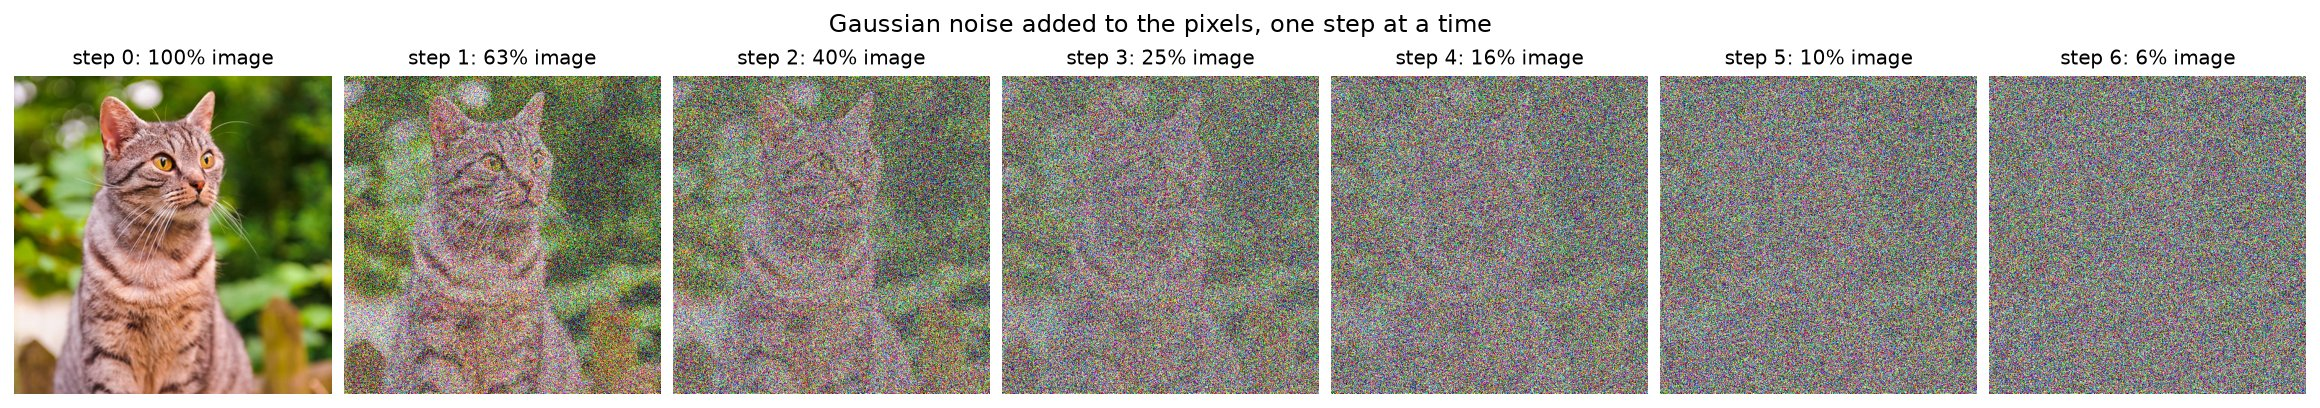

In [2]:
STEPS, BETA = 6, 0.6


def add_noise(x, steps=STEPS, beta=BETA, seed=0):
    # returns [x_0, x_1, ..., x_steps]: one step of x_k = sqrt(1 - beta) x_{k-1} + sqrt(beta) noise at a time
    generator = torch.Generator(x.device).manual_seed(seed)
    xs = [x]
    for _ in range(steps):
        noise = torch.randn(x.shape, generator=generator, device=x.device)
        xs.append((1 - beta) ** 0.5 * xs[-1] + beta ** 0.5 * noise)
    return xs


def show(x):
    # (1, 3, H, W) in [-1, 1] -> (H, W, 3) in [0, 1]; values outside the range are clipped
    return ((x[0].permute(1, 2, 0) + 1) / 2).clamp(0, 1).cpu().numpy()


def step_title(k):
    return f"step {k}: {(1 - BETA) ** (k / 2):.0%} image"


pixel_steps = add_noise(x0)
fig, axes = plt.subplots(1, STEPS + 1, figsize=(16, 2.9), layout="constrained")
for k, ax in enumerate(axes):
    ax.imshow(show(pixel_steps[k]))
    ax.set_title(step_title(k), fontsize=10)
    ax.axis("off")
fig.suptitle("Gaussian noise added to the pixels, one step at a time", fontsize=12)
plt.show()

Every pixel gets its own independent noise, so the image dissolves into colored static. Large, high-contrast
shapes (the outline of the cat against the green background) survive longest, until about step 3; fine detail such as
the whiskers and the fur stripes fades first. The title gives $\sqrt{\bar\alpha_k}$, the share of the original image still in
$x_k$.

## 2. Noise on the latent

Stable Diffusion 3.5 does not add noise to pixels. Its VAE encoder first compresses the 3 × 512 × 512 image into a
16 × 64 × 64 latent, and the latent is normalized so that its values have about mean 0 and standard deviation 1,
like the noise: $z = (\text{latent} - 0.0609) \cdot 1.5305$ (`shift_factor`, `scaling_factor`).

latent: (1, 16, 64, 64) mean -0.11, std 1.10


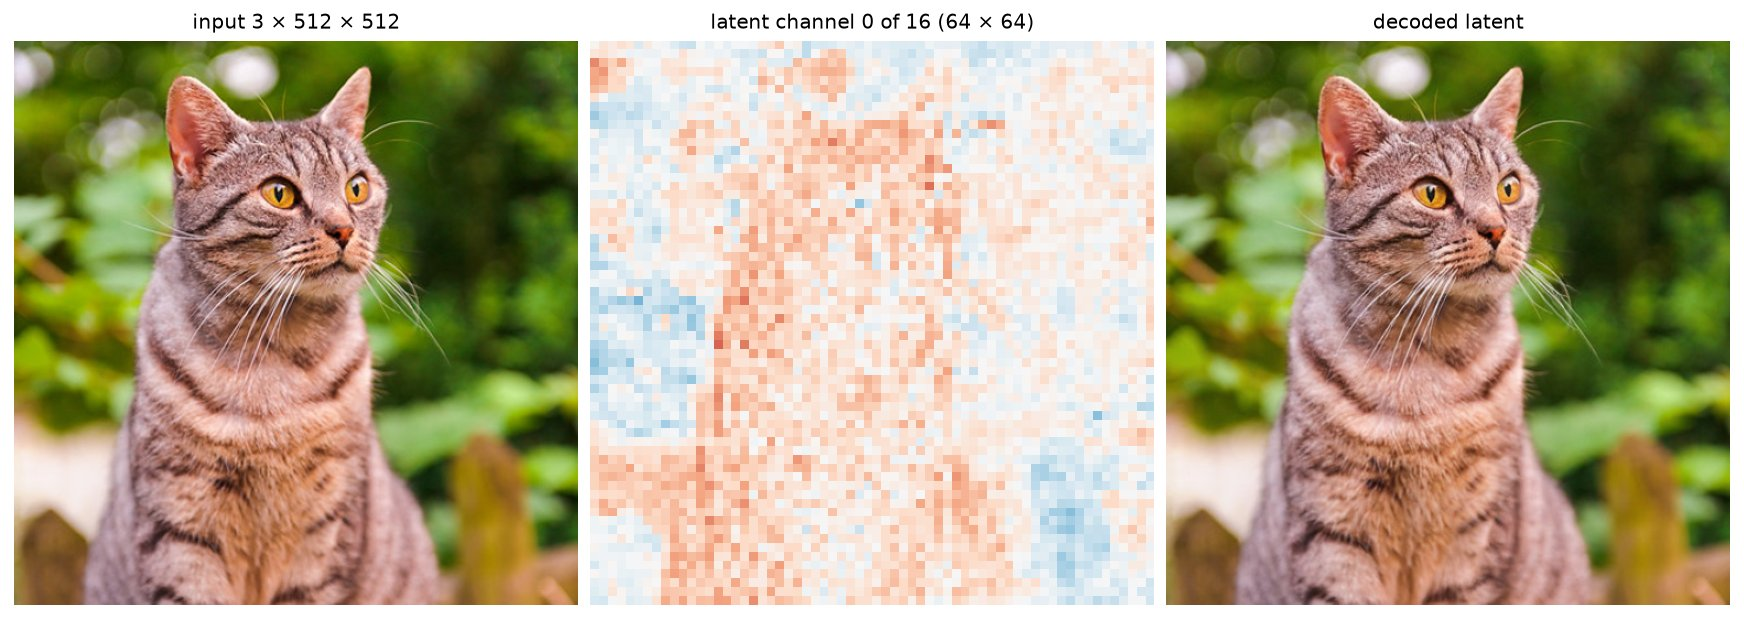

In [3]:
def encode(x):
    return (vae.encode(x).latent_dist.mean - vae.config.shift_factor) * vae.config.scaling_factor


def decode(z):
    return vae.decode(z / vae.config.scaling_factor + vae.config.shift_factor).sample


z0 = encode(x0)
print("latent:", tuple(z0.shape), f"mean {z0.mean():.2f}, std {z0.std():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), layout="constrained")
for ax, image, title in [(axes[0], show(x0), "input 3 × 512 × 512"),
                         (axes[1], z0[0, 0].cpu(), "latent channel 0 of 16 (64 × 64)"),
                         (axes[2], show(decode(z0)), "decoded latent")]:
    ax.imshow(image, cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.show()

The same 6 steps with the same $\beta$, now on the latent. Each noisy latent $z_k$ is shown as one of its
channels (top) and as the image the VAE decoder makes of it (bottom).

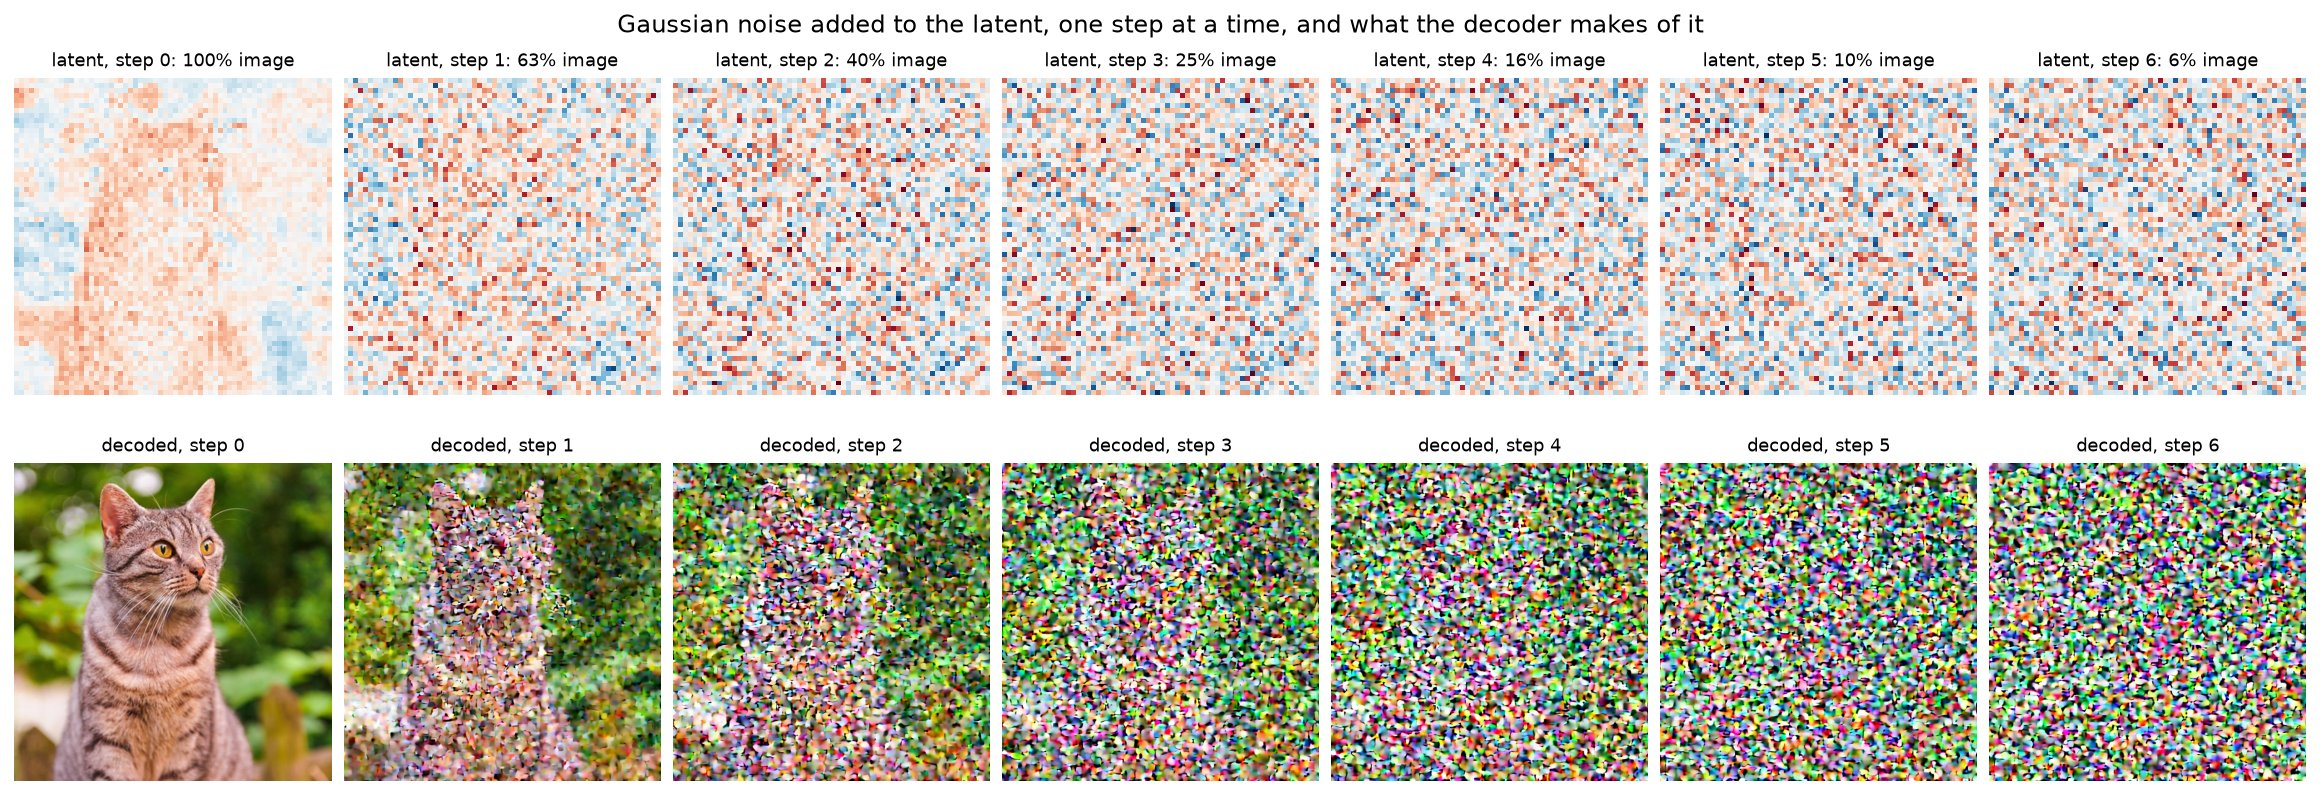

In [4]:
latent_steps = add_noise(z0)
decoded_steps = [decode(z) for z in latent_steps]

fig, axes = plt.subplots(2, STEPS + 1, figsize=(16, 5.6), layout="constrained")
for k in range(STEPS + 1):
    axes[0, k].imshow(latent_steps[k][0, 0].cpu(), cmap="RdBu_r", vmin=-3, vmax=3)
    axes[0, k].set_title(f"latent, {step_title(k)}", fontsize=9)
    axes[1, k].imshow(show(decoded_steps[k]))
    axes[1, k].set_title(f"decoded, step {k}", fontsize=9)
    for row in (0, 1):
        axes[row, k].axis("off")
fig.suptitle("Gaussian noise added to the latent, one step at a time, and what the decoder makes of it", fontsize=12)
plt.show()

Side by side, step by step: pixels with noise (top) and decoded latents with noise (bottom).

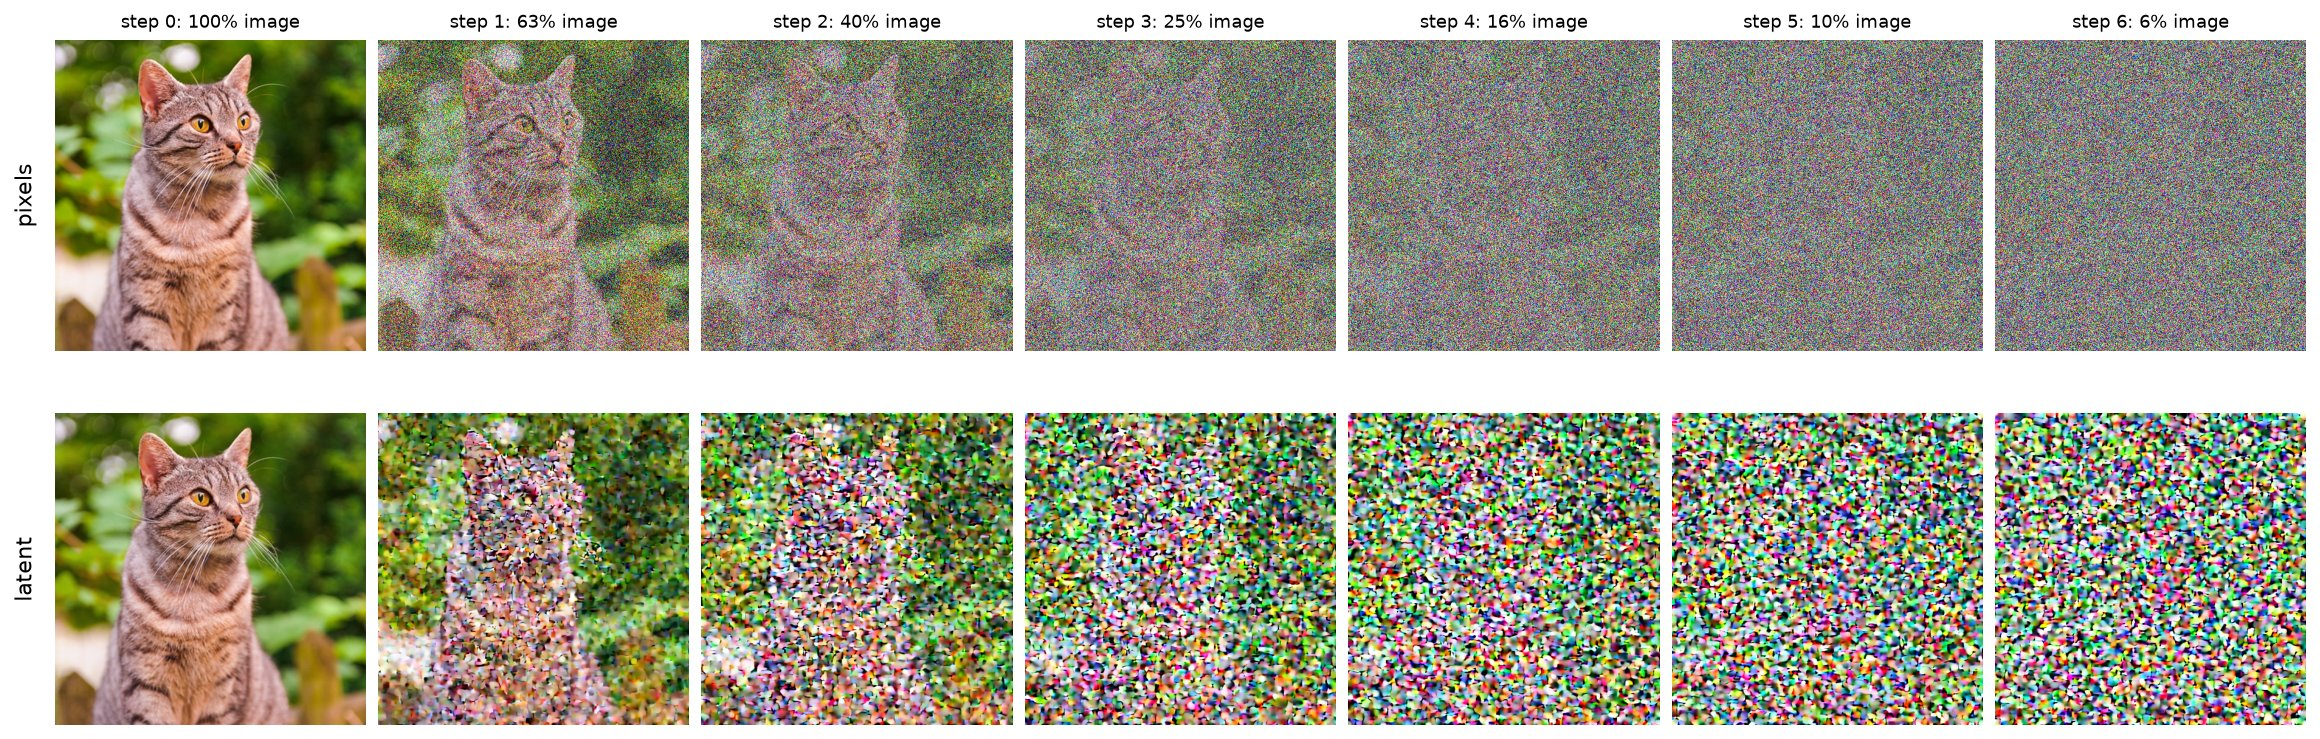

In [5]:
fig, axes = plt.subplots(2, STEPS + 1, figsize=(16, 5.2), layout="constrained")
for col, k in enumerate(range(STEPS + 1)):
    axes[0, col].imshow(show(pixel_steps[k]))
    axes[0, col].set_title(step_title(k), fontsize=9)
    axes[1, col].imshow(show(decoded_steps[k]))
    for row in (0, 1):
        axes[row, col].axis("off")
axes[0, 0].text(-30, SIZE / 2, "pixels", rotation=90, ha="right", va="center", fontsize=11)
axes[1, 0].text(-30, SIZE / 2, "latent", rotation=90, ha="right", va="center", fontsize=11)
plt.show()

What changes when the noise goes into the latent:

- **The noise is not static any more.** One latent value describes an 8 × 8 patch of pixels, and the decoder only
  knows how to produce image-like content. Gaussian noise in the latent comes out as blotches and textures, not as
  independent speckles per pixel.
- **The details go first, and faster.** The latent is compact: every value matters, and with the latent normalized
  to standard deviation 1 (the pixels here have about 0.5), the same noise is relatively larger. After one step the
  eyes and stripes are already gone from the decoded latent, while the cat's outline lasts until about step 3, about
  as long as in the pixels.
- **The end point is the same:** after enough steps $z_k$ is (almost) pure $\mathcal{N}(0, I)$ noise. That is where
  generation starts: the diffusion Transformer learns to walk these steps backwards in the latent, and the VAE
  decoder turns the final clean latent into pixels.

Stable Diffusion 3.5 uses a slightly different mix than the one above, *rectified flow*:
$z_t = (1 - t)\, z_0 + t\, \varepsilon$ for $t$ from 0 to 1 (a straight line from the image to the noise), and it
picks a random $t$ for every training example instead of stepping (StableDiffusionArchitecture notebook). The picture
is the same: the further along, the less image and the more noise.